# Task 3 — From-scratch deep learning on spending regression

Compare three PyTorch tabular models on the existing `eda_combined_v1` dataset: a plain direct MLP, a residual direct MLP, and a residual zero-aware hurdle MLP. All weights train from scratch using only competition Train/Validation rows. The original 20% holdout and five development folds exactly match `build_model_v2.ipynb`. Fold scores are the primary comparison because that holdout has already informed earlier choices. All figures are **MAE in THB**, lower is better; the competition's NMAE denominator is unavailable.

Each model cell loads complete artifacts or performs its own fold fits, development fit, save, and holdout evaluation. Per-fold OOF files guard expensive training. Preprocessing and early stopping are fitted only within training rows of each fold. Test is not read.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents)
          if (p/"src"/"pipeline"/"save_model.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.pipeline.random_seed import set_seed
SEED=set_seed(include_torch=True)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split,StratifiedKFold
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.pipeline.read_evalutate_summarize import read_evaluation_index
from src.task3.models.neural_models import NeuralSpendingRegressor

sns.set_theme(style="whitegrid")
SRC=ROOT/"src"
TASK=SRC/"task3"
DATA_NAME="eda_combined_v1"
TARGET,ID="spending_30d","player_id"
card=json.loads((TASK/"data"/"eda"/f"{DATA_NAME}.json").read_text(encoding="utf-8"))
train=pd.read_parquet(SRC/card["splits"]["train"]["path"])
assert len(train)==card["splits"]["train"]["rows"] and train[ID].is_unique
features=[c for c in train.columns if c not in (ID,TARGET)]
assert len(features)==48 and train[TARGET].notna().all()
y=train[TARGET].astype(float)
bands=pd.cut(y,bins=[-1,0,100,1000,10000,50000,np.inf],labels=False)
dev_idx,valid_idx=train_test_split(np.arange(len(y)),test_size=.20,
    stratify=bands,random_state=SEED)
X_dev=train.iloc[dev_idx][features].reset_index(drop=True)
y_dev=y.iloc[dev_idx].reset_index(drop=True)
X_valid=train.iloc[valid_idx][features]
y_valid=y.iloc[valid_idx]
dev_bands=bands.iloc[dev_idx].reset_index(drop=True)
splits=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(X_dev,dev_bands))
assert len(X_dev)==83200 and len(X_valid)==20800 and len(splits)==5
RESULTS=TASK/"models"/"results"
SAVE=TASK/"save"
MODULE_HASH=hashlib.sha256((TASK/"models"/"neural_models.py").read_bytes()).hexdigest()
print("Torch:",torch.__version__,"CUDA:",torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Development/holdout:",len(X_dev),len(X_valid),"zero share:",round((y_dev==0).mean(),4))

Torch: 2.11.0+cu128 CUDA: True NVIDIA GeForce RTX 3050 Ti Laptop GPU
Development/holdout: 83200 20800 zero share: 0.4812


## 1. Reproduce the existing development-fold reference

Read the cached CatBoost/LightGBM and zero-aware fold predictions. The weights and gate threshold come from the saved model cards, so this notebook does not depend on variables in another notebook.

In [2]:
def model_card(name):
    return json.loads((SAVE/f"{name}.json").read_text(encoding="utf-8"))
gate_weight=float(model_card("t3_gate_blend_cv5_v2")["card"]["gate_weight"])
cat_weight=float(model_card("t3_cat_lgb_blend_cv5_v2")["card"]["catboost_weight"])
gate_threshold=float(model_card("t3_positive_gate_cv5_v2")["card"]["threshold"])
old_parts=[]
for fold,(_,check_pos) in enumerate(splits,1):
    gate=pd.read_parquet(RESULTS/f"round3_gate_fold{fold}_v1.parquet")
    blend=pd.read_parquet(RESULTS/f"round3_blend_fold{fold}_v1.parquet")
    assert gate.row_pos.tolist()==check_pos.tolist()==blend.row_pos.tolist()
    assert gate.true.equals(blend.true)
    gate_pred=np.where(gate.probability>=gate_threshold,np.maximum(gate.positive_amount,0),0)
    blend_pred=np.maximum(cat_weight*blend.cat+(1-cat_weight)*blend.lgb,0)
    prediction=gate_weight*gate_pred+(1-gate_weight)*blend_pred
    old_parts.append(pd.DataFrame({"fold":fold,"row_pos":check_pos,
        "true":gate.true.to_numpy(),"prediction":prediction}))
reference_oof=pd.concat(old_parts,ignore_index=True)
reference_folds=(reference_oof.groupby("fold")
    .apply(lambda g:mean_absolute_error(g.true,g.prediction),include_groups=False))
print("Reference weights:",gate_weight,cat_weight,"gate threshold:",gate_threshold)
display(reference_folds.rename("MAE_thb").to_frame().round(2))
print("Reference mean fold MAE:",round(reference_folds.mean(),2))
assert abs(reference_folds.mean()-2895.92)<.2

Reference weights: 0.8 0.4 gate threshold: 0.5


,MAE_thb
fold,
1,2815.58
2,2973.69
3,2797.07
4,2929.51
5,2963.76


Reference mean fold MAE: 2895.92


## 2. Deep-learning configurations and guarded experiment helper

The plain versus residual architecture checks representation capacity. The hurdle model handles zero spending explicitly. These three settings are a focused tuning round, not an exhaustive AutoML search. Each network uses an internal 12% split for early stopping, signed-log scaled numeric inputs, missing indicators, and one-hot nominal fields; all fitted preprocessing stays inside its training rows.

In [3]:
CONFIGS={
    "plain_direct":{"architecture":"plain","objective":"direct","width":128,
                    "depth":2,"dropout":.10,"learning_rate":.001,
                    "weight_decay":.0001,"batch_size":1024,"max_epochs":45,"patience":6},
    "residual_direct":{"architecture":"residual","objective":"direct","width":192,
                       "depth":3,"dropout":.15,"learning_rate":.0007,
                       "weight_decay":.0001,"batch_size":1024,"max_epochs":50,"patience":7},
    "residual_hurdle":{"architecture":"residual","objective":"hurdle","width":192,
                       "depth":3,"dropout":.15,"learning_rate":.0007,
                       "weight_decay":.0001,"batch_size":1024,"max_epochs":50,"patience":7},
}

def run_model(label):
    config=CONFIGS[label]
    name=f"t3_{label}_cv5_v3"
    model_path,card_path,eval_path=(SAVE/f"{name}.joblib",SAVE/f"{name}.json",SAVE/f"{name}-evaluation.json")
    key={"dataset":DATA_NAME,"dataset_created_at":card["created_at"],
         "module_sha256":MODULE_HASH,"seed":SEED,"folds":5,"config":config}
    parts=[]
    for fold,(fit_pos,check_pos) in enumerate(splits,1):
        path=RESULTS/f"{name}-fold{fold}.parquet"
        meta=RESULTS/f"{name}-fold{fold}.json"
        if path.exists()!=meta.exists(): raise RuntimeError(f"Incomplete fold {fold}: {name}")
        if path.exists():
            assert json.loads(meta.read_text(encoding="utf-8"))=={"key":key,"fold":fold}
            part=pd.read_parquet(path)
            print("Loaded",name,"fold",fold)
        else:
            if model_path.exists() or card_path.exists() or eval_path.exists():
                raise RuntimeError(f"Saved result but missing fold {fold}: {name}")
            model=NeuralSpendingRegressor(**config,random_state=SEED+fold)
            model.fit(X_dev.iloc[fit_pos],y_dev.iloc[fit_pos])
            probability,amount=model.predict_components(X_dev.iloc[check_pos])
            part=pd.DataFrame({"fold":fold,"row_pos":check_pos,
                "true":y_dev.iloc[check_pos].to_numpy(),"amount":amount,
                "probability":np.nan if probability is None else probability,
                "best_epoch":model.best_epoch_})
            RESULTS.mkdir(parents=True,exist_ok=True)
            part.to_parquet(path,index=False)
            meta.write_text(json.dumps({"key":key,"fold":fold},indent=2),encoding="utf-8")
            print("Trained",name,"fold",fold,"epoch",model.best_epoch_)
        assert part.row_pos.tolist()==check_pos.tolist()
        assert np.array_equal(part.true.to_numpy(),y_dev.iloc[check_pos].to_numpy())
        parts.append(part)
    oof=pd.concat(parts,ignore_index=True)
    assert len(oof)==len(X_dev) and oof.row_pos.is_unique
    if config["objective"]=="hurdle":
        # Select threshold on four development folds, check on the fifth.
        grid=np.round(np.arange(.35,.651,.05),2)
        cv_rows=[]
        for check_fold in range(1,6):
            tune=oof[oof.fold!=check_fold]
            check=oof[oof.fold==check_fold]
            losses=[mean_absolute_error(tune.true,
                np.where(tune.probability>=t,np.maximum(tune.amount,0),0)) for t in grid]
            chosen=float(grid[int(np.argmin(losses))])
            checked=np.where(check.probability>=chosen,np.maximum(check.amount,0),0)
            cv_rows.append({"fold":check_fold,"threshold":chosen,
                            "MAE_thb":mean_absolute_error(check.true,checked)})
        cv_scores=pd.DataFrame(cv_rows)
        all_losses=[mean_absolute_error(oof.true,
            np.where(oof.probability>=t,np.maximum(oof.amount,0),0)) for t in grid]
        final_threshold=float(grid[int(np.argmin(all_losses))])
    else:
        cv_scores=pd.DataFrame([{"fold":int(fold),"threshold":None,
            "MAE_thb":mean_absolute_error(g.true,np.maximum(g.amount,0))}
            for fold,g in oof.groupby("fold")])
        final_threshold=None
    cv_mean=float(cv_scores.MAE_thb.mean())
    if model_path.exists() and card_path.exists() and eval_path.exists():
        saved_card=json.loads(card_path.read_text(encoding="utf-8"))
        result=json.loads(eval_path.read_text(encoding="utf-8"))
        assert saved_card["data_name"]==DATA_NAME and saved_card["card"]["config"]==config
        assert result["metric"]=="MAE_thb"
        model=joblib.load(model_path)
        print("Loaded saved model:",name)
    elif model_path.exists() or card_path.exists() or eval_path.exists():
        raise RuntimeError(f"Incomplete saved model: {name}")
    else:
        model=NeuralSpendingRegressor(**config,random_state=SEED,
            gate_threshold=.5 if final_threshold is None else final_threshold)
        model.fit(X_dev,y_dev)
        prediction=np.maximum(model.predict(X_valid),0)
        save_model(task=3,name=name,model=model,data_name=DATA_NAME,
            card={"idea":f"From-scratch PyTorch {label} on Task 3 tabular data",
                  "config":config,"seed":SEED,"folds":5,
                  "development_cv_mean_MAE_thb":cv_mean,
                  "gate_threshold":final_threshold,
                  "full_dev_best_epoch":model.best_epoch_,
                  "metric_note":"MAE THB; NMAE denominator unavailable"})
        result=evaluate_model(task=3,name=name,score=mean_absolute_error(y_valid,prediction),
            metric_name="MAE_thb",higher_is_better=False,
            card={"split":"original stratified 20% holdout; reused for earlier Task 3 comparisons",
                  "seed":SEED,"development_cv_MAE_thb":cv_scores.to_dict("records"),
                  "gate_threshold_selected_on":"development folds only" if final_threshold is not None else None})
        print("Saved model and holdout evaluation:",name)
    holdout_prediction=np.maximum(model.predict(X_valid),0)
    holdout_mae=float(mean_absolute_error(y_valid,holdout_prediction))
    assert abs(holdout_mae-result["score"])<.05
    print(name,"CV mean MAE:",round(cv_mean,2),"holdout MAE:",round(holdout_mae,2),
          "threshold:",final_threshold)
    return oof,cv_scores,model

## 3. Plain MLP, direct MAE target

In [4]:
plain_oof,plain_scores,plain_model=run_model("plain_direct")

Trained t3_plain_direct_cv5_v3 fold 1 epoch 20


Trained t3_plain_direct_cv5_v3 fold 2 epoch 24


Trained t3_plain_direct_cv5_v3 fold 3 epoch 31


Trained t3_plain_direct_cv5_v3 fold 4 epoch 30


Trained t3_plain_direct_cv5_v3 fold 5 epoch 19


Saved model and holdout evaluation: t3_plain_direct_cv5_v3
t3_plain_direct_cv5_v3 CV mean MAE: 3168.78 holdout MAE: 3039.08 threshold: None


## 4. Residual MLP, direct MAE target

In [5]:
residual_oof,residual_scores,residual_model=run_model("residual_direct")

Trained t3_residual_direct_cv5_v3 fold 1 epoch 13


Trained t3_residual_direct_cv5_v3 fold 2 epoch 18


Trained t3_residual_direct_cv5_v3 fold 3 epoch 18


Trained t3_residual_direct_cv5_v3 fold 4 epoch 15


Trained t3_residual_direct_cv5_v3 fold 5 epoch 15


Saved model and holdout evaluation: t3_residual_direct_cv5_v3
t3_residual_direct_cv5_v3 CV mean MAE: 3257.12 holdout MAE: 3219.51 threshold: None


## 5. Residual MLP, zero-aware two-head objective

In [6]:
hurdle_oof,hurdle_scores,hurdle_model=run_model("residual_hurdle")

Trained t3_residual_hurdle_cv5_v3 fold 1 epoch 24


Trained t3_residual_hurdle_cv5_v3 fold 2 epoch 25


Trained t3_residual_hurdle_cv5_v3 fold 3 epoch 23


Trained t3_residual_hurdle_cv5_v3 fold 4 epoch 21


Trained t3_residual_hurdle_cv5_v3 fold 5 epoch 22


Saved model and holdout evaluation: t3_residual_hurdle_cv5_v3
t3_residual_hurdle_cv5_v3 CV mean MAE: 3215.6 holdout MAE: 3091.39 threshold: 0.5


## 6. Paired fold and holdout comparison

The five-fold development comparison is primary. The reused holdout is a separate exploratory check. An MLP that loses clearly to the existing zero-aware mixture is evidence to stop this deep-learning branch rather than adding many unmotivated architectures.

,model,mean_CV_MAE_thb,std_CV_MAE_thb,delta_vs_existing
0,existing_gate_blend,2895.92,83.67,0.00
1,plain_direct,3168.78,114.24,272.86
3,residual_hurdle,3215.60,101.21,319.68
2,residual_direct,3257.12,98.68,361.20


model,existing_gate_blend,plain_direct,residual_direct,residual_hurdle
fold,,,,
1,2815.58,3145.65,3192.92,3133.27
2,2973.69,3322.58,3349.93,3319.03
3,2797.07,3023.46,3165.70,3100.67
4,2929.51,3117.84,3199.42,3208.26
5,2963.76,3234.35,3377.65,3316.76


,model,holdout_MAE_thb
0,t3_gate_blend_cv5_v2,2845.10
1,t3_plain_direct_cv5_v3,3039.08
3,t3_residual_hurdle_cv5_v3,3091.39
2,t3_residual_direct_cv5_v3,3219.51


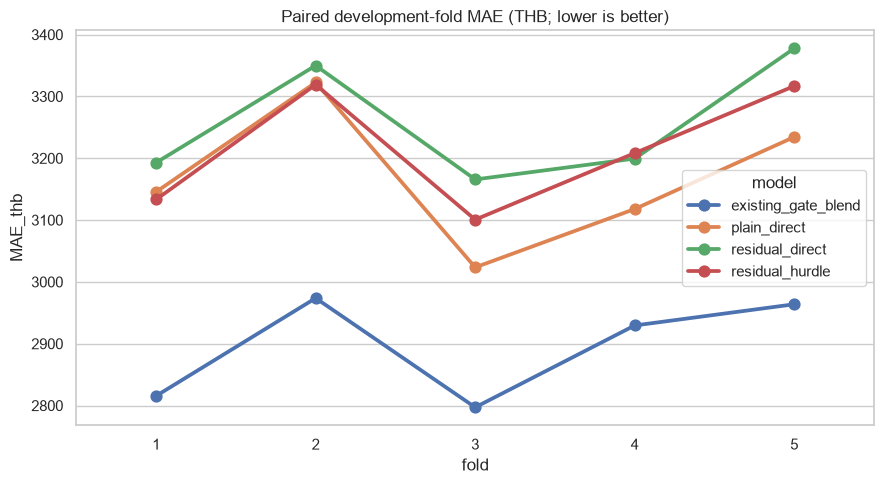

In [7]:
fold_table=pd.concat([
    reference_folds.rename("MAE_thb").reset_index().assign(model="existing_gate_blend"),
    plain_scores[["fold","MAE_thb"]].assign(model="plain_direct"),
    residual_scores[["fold","MAE_thb"]].assign(model="residual_direct"),
    hurdle_scores[["fold","MAE_thb"]].assign(model="residual_hurdle"),
],ignore_index=True)
summary=(fold_table.groupby("model",as_index=False)
         .agg(mean_CV_MAE_thb=("MAE_thb","mean"),std_CV_MAE_thb=("MAE_thb","std")))
summary["delta_vs_existing"]=summary.mean_CV_MAE_thb-reference_folds.mean()
display(summary.sort_values("mean_CV_MAE_thb").round(2))
display(fold_table.pivot(index="fold",columns="model",values="MAE_thb").round(2))
index=read_evaluation_index(3)["evaluations"]
names=["t3_gate_blend_cv5_v2"]+[f"t3_{label}_cv5_v3" for label in CONFIGS]
display(pd.DataFrame([{"model":name,"holdout_MAE_thb":index[name]["score"]} for name in names])
        .sort_values("holdout_MAE_thb").round(2))

fig,ax=plt.subplots(figsize=(9,5))
sns.pointplot(data=fold_table,x="fold",y="MAE_thb",hue="model",ax=ax)
ax.set(title="Paired development-fold MAE (THB; lower is better)")
plt.tight_layout();plt.show()

## 7. Where the best neural model errs

Inspect zero, positive, and high-spend targets on the reused holdout. This is diagnostic and does not turn the holdout into fresh validation. The existing model's corresponding breakdown is in `build_model_v2.ipynb` and the research note.

In [8]:
models={"plain_direct":plain_model,"residual_direct":residual_model,
        "residual_hurdle":hurdle_model}
best_label=summary.sort_values("mean_CV_MAE_thb").iloc[0]["model"]
if best_label=="existing_gate_blend":
    best_neural=min((k for k in models),key=lambda k:summary.set_index("model").loc[k,"mean_CV_MAE_thb"])
else:
    best_neural=best_label
pred=np.maximum(models[best_neural].predict(X_valid),0)
bands_valid=pd.cut(y_valid,bins=[-1,0,100,1000,10000,50000,np.inf],
                   labels=["zero","(0,100]","(100,1k]","(1k,10k]","(10k,50k]","50k+"])
error_table=pd.DataFrame({"true":y_valid.to_numpy(),"prediction":pred,
                          "band":bands_valid.to_numpy()})
error_table["absolute_error"]=(error_table.true-error_table.prediction).abs()
band_summary=(error_table.groupby("band",observed=True)
              .agg(accounts=("true","size"),MAE_thb=("absolute_error","mean"),
                   total_error=("absolute_error","sum")))
band_summary["error_share_pct"]=100*band_summary.total_error/error_table.absolute_error.sum()
print("Best neural configuration by development CV:",best_neural)
display(band_summary.round(2))

Best neural configuration by development CV: plain_direct


,accounts,MAE_thb,total_error,error_share_pct
band,,,,
"(0,100]",501,50.03,25064.43,0.04
"(100,1k]",2822,304.90,860432.47,1.36
"(10k,50k]",1118,5045.41,5640768.62,8.92
"(1k,10k]",4652,805.88,3748932.27,5.93
50k+,1697,21105.58,35816162.38,56.66
zero,10010,1710.44,17121498.44,27.09
